In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import date
from datetime import datetime

# for time series decomposition
from statsmodels.tsa.seasonal import seasonal_decompose

# stationarity tests
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.stattools import kpss

# autocorrelation plots
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

In [3]:
# create a datetime object from a string
datetime.strptime('2004-01-02 09:00:00', '%Y-%m-%d %H:%M:%S')

datetime.datetime(2004, 1, 2, 9, 0)

## Time series smoothing

In [4]:
# read data, parsing the column "date" as a date
df = pd.read_csv('data/foursquare_groupedNewYork.csv',
                 parse_dates=['date'],
                 usecols=['date', 'categoryname', 'demo', 'visits'])
# make sure that records are sorted by date
df = df.sort_values(by='date')
# select the data about the visits to grocery stores
df = df[(df['categoryname']=='Grocery') & (df['demo']=='All')]
df = df[['date','visits']]

/var/folders/q2/y4726bh527bcznrqcvx4tlp40000gn/T/ipykernel_57126/1066551960.py:8: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_yticklabels([0,'1M','2M','3M','4M'])


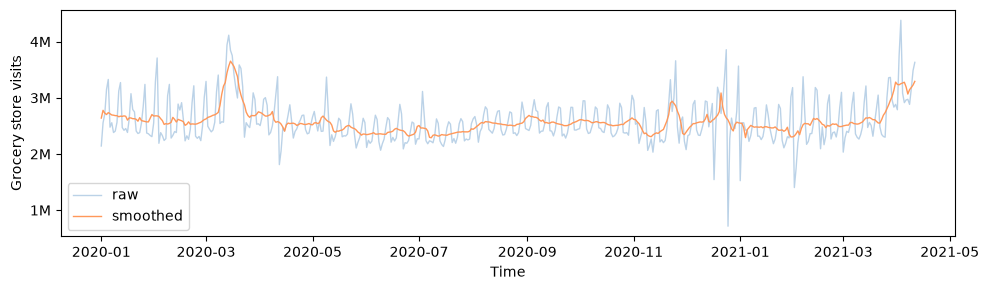

In [5]:
# apply smoothing on a 7-day rolling window
df_smooth = df.rolling(window=7, min_periods=1, on='date', center=True).mean()

# plotting the original and smoothed curves
fig,ax = plt.subplots(1,1,figsize=(10,3))
plt.plot(df['date'],df['visits'],'-',linewidth=1,alpha=0.7,label='raw',color='#9FC0DE')
plt.plot(df_smooth['date'],df_smooth['visits'],'-',linewidth=1,label='smoothed',color='#FF985A')
ax.set_yticklabels([0,'1M','2M','3M','4M'])
ax.set_ylabel('Grocery store visits')
ax.set_xlabel('Time')
plt.legend()
plt.tight_layout()
plt.savefig('foursquare_groceries.png', dpi=400)

## Time series decomposition

In [6]:
# load the data
df = pd.read_csv('data/foursquare_groupedNewYork.csv', parse_dates=['date'], usecols=['date', 'categoryname', 'demo', 'visits'])
# sort by date
df = df.sort_values(by='date')
# select the category 'Outdoors & Recreation'
df = df[(df['categoryname']=='Outdoors & Recreation') & (df['demo']=='All')]
df = df[['date','visits']]

/var/folders/q2/y4726bh527bcznrqcvx4tlp40000gn/T/ipykernel_57126/2939592401.py:8: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_yticklabels([0,'2M','3M','4M','5M'])


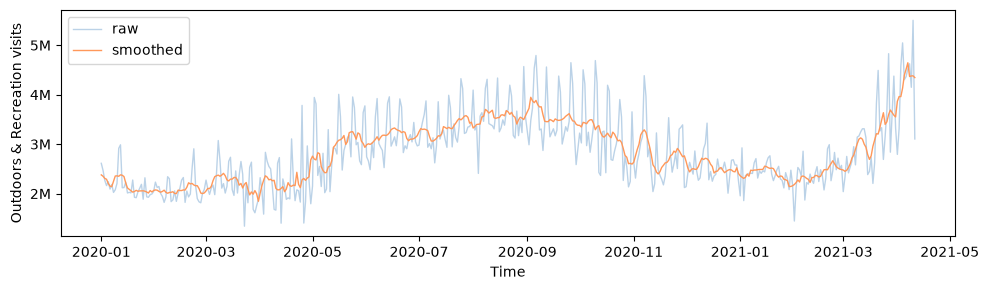

In [7]:
# smoothing
df_smooth = df.rolling(window=7,min_periods=1,on='date',center=True).mean()

# plotting
fig,ax = plt.subplots(1,1,figsize=(10,3))
ax.plot(df['date'],df['visits'],'-',linewidth=1,alpha=0.7,label='raw',color='#9FC0DE')
ax.plot(df_smooth['date'],df_smooth['visits'],'-',linewidth=1,label='smoothed',color='#FF985A')
ax.set_yticklabels([0,'2M','3M','4M','5M'])
ax.set_ylabel('Outdoors & Recreation visits')
ax.set_xlabel('Time')
plt.legend()
plt.tight_layout()
plt.savefig('foursquare_outdoors.png', dpi=400)

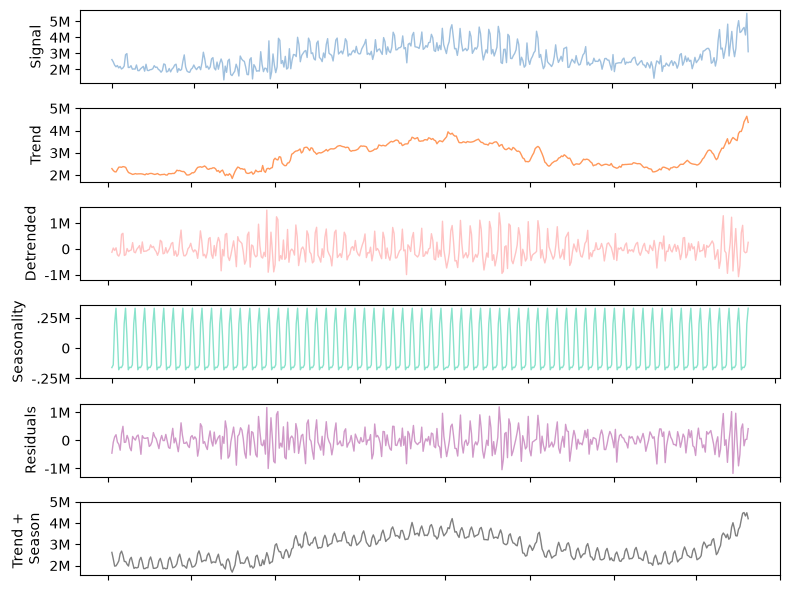

In [8]:
# decompose the time series
decomposition_result = seasonal_decompose(df['visits'], model='additive', period=7)
observed = decomposition_result.observed
seasonal = decomposition_result.seasonal
trend = decomposition_result.trend
resid = decomposition_result.resid

# plotting the different components
fig,axs = plt.subplots(6,1,figsize=(8,6))
axs[0].plot(df['date'],observed,'-',linewidth=1,label='raw',color='#9FC0DE')
axs[0].set_yticks([2000000,3000000,4000000,5000000])
axs[0].set_yticklabels(['2M','3M','4M','5M'])
axs[0].set_ylabel('Signal')
axs[1].plot(df['date'],trend,'-',linewidth=1,label='raw',color='#FF985A')
axs[1].set_yticks([2000000,3000000,4000000,5000000])
axs[1].set_yticklabels(['2M','3M','4M','5M'])
axs[1].set_ylabel('Trend')
axs[2].plot(df['date'],observed-trend,'-',linewidth=1,label='raw',color='#FFC3C3')
axs[2].set_yticks([-1000000,0,1000000])
axs[2].set_yticklabels(['-1M','0','1M'])
axs[2].set_ylabel('Detrended')
axs[3].plot(df['date'],seasonal,'-',linewidth=1,label='raw',color='#89E3CC')
axs[3].set_yticks([-250000,0,250000])
axs[3].set_yticklabels(['-.25M','0','.25M'])
axs[3].set_ylabel('Seasonality')
axs[4].plot(df['date'],resid,'-',linewidth=1,alpha=0.8,label='raw',color='#C580BB')
axs[4].set_yticks([-1000000,0,1000000])
axs[4].set_yticklabels(['-1M','0','1M'])
axs[4].set_ylabel('Residuals')
axs[5].plot(df['date'],trend+seasonal,'-',linewidth=1,alpha=0.5,label='raw',color='black')
axs[5].set_yticks([2000000,3000000,4000000,5000000])
axs[5].set_yticklabels(['2M','3M','4M','5M'])
axs[5].set_ylabel('Trend + \nSeason')
for ax in axs:
    #ax.set_yticks([])
    ax.set_xticklabels([])
plt.tight_layout()
plt.savefig('timeseries_decomposition.png', dpi=400)

## Making a time series stationary

In [9]:
import statsmodels
statsmodels.__version__

'0.15.0'

In [10]:
# load the data again
df = pd.read_csv('data/foursquare_groupedNewYork.csv', parse_dates=['date'], usecols=['date', 'categoryname', 'demo', 'visits'])
df = df.sort_values(by='date')
df = df[(df['categoryname']=='Outdoors & Recreation') & (df['demo']=='All')]
df = df[['date','visits']]

In [11]:
# apply different types of time series transformations
df['visits_log'] = df['visits'].apply(np.log)
df['visits_sqrt'] = df['visits'].apply(np.sqrt)
df['visits_diff'] = df['visits'] - df['visits'].shift(1)

df['visits_return'] = df['visits'] / df['visits'].shift(1)
df['visits_return_log'] = df['visits_return'].apply(np.log)

df['visits_log_diff'] = df['visits_log'] - df['visits_log'].shift(1)
df['visits_sqrt_diff'] = df['visits_sqrt'] - df['visits_sqrt'].shift(1)

df.head()

,date,visits,visits_log,visits_sqrt,visits_diff,visits_return,visits_return_log,visits_log_diff,visits_sqrt_diff
70,2020-01-01,2612419.0,14.775787,1616.297930,NaN,NaN,NaN,NaN,NaN
169,2020-01-02,2469744.0,14.719625,1571.541918,-142675.0,0.945386,-0.056162,-0.056162,-44.756012
268,2020-01-03,2268873.0,14.634794,1506.277863,-200871.0,0.918667,-0.084831,-0.084831,-65.264055
364,2020-01-04,2162264.0,14.586666,1470.463872,-106609.0,0.953012,-0.048127,-0.048127,-35.813990
460,2020-01-05,2241088.0,14.622472,1497.026386,78824.0,1.036454,0.035806,0.035806,26.562513


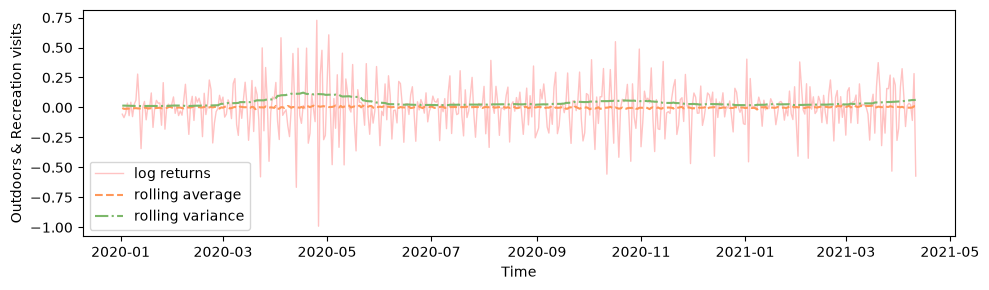

In [12]:
# select one specific transformation
var = 'visits_return_log'

# calculate the rolling average and variance
df_plot = df[['date',var]].dropna()
df_avg = df[var].dropna().rolling(window=50,min_periods=1,center=True).mean()
df_std = df[var].dropna().rolling(window=50,min_periods=1,center=True).var()

# plotting transformed time series and rolling avg and std
fig,ax = plt.subplots(1,1,figsize=(10,3))
ax.plot(df_plot['date'],df_plot[var],'-',linewidth=1,label='log returns',color='#FFC3C3')
ax.plot(df_plot['date'],df_avg,'--',label='rolling average',color='#FF985A')
ax.plot(df_plot['date'],df_std,'-.',label='rolling variance',color='#7CB86A')
ax.set_ylabel('Outdoors & Recreation visits')
ax.set_xlabel('Time')
plt.legend()
plt.tight_layout()
plt.savefig('foursquare_outdoors_log_returns.png', dpi=400)

In [13]:
# statistical tests to check for stationarity
print(" > Is the data stationary ?")
dftest = adfuller(df_plot[var], autolag='AIC')
print("Test statistic = {:.8f}".format(dftest[0]))
print("P-value = {:.8f}".format(dftest[1]))
print("Critical values :")
for k, v in dftest[4].items():
    print("\t{}: {} - The data is {} stationary with {}% confidence".format(k, v, "not" if v<dftest[0] else "", 100-int(k[:-1])))

print(" > Is the data stationary ?")
kpss_test = kpss_test = kpss(df_plot[var])
print("Test statistic = {:.8f}".format(kpss_test[0]))
print("P-value = {:.8f}".format(kpss_test[1]))

 > Is the data stationary ?
Test statistic = -5.99769225
P-value = 0.00000017
Critical values :
	1%: -3.4450642060791097 - The data is  stationary with 99% confidence
	5%: -2.868027634065253 - The data is  stationary with 95% confidence
	10%: -2.5702256691640515 - The data is  stationary with 90% confidence
 > Is the data stationary ?
Test statistic = 0.09337505
P-value = 0.10000000


/var/folders/q2/y4726bh527bcznrqcvx4tlp40000gn/T/ipykernel_57126/1635974786.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  dftest = adfuller(df_plot[var], autolag='AIC')
/var/folders/q2/y4726bh527bcznrqcvx4tlp40000gn/T/ipykernel_57126/1635974786.py:11: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_test = kpss_test = kpss(df_plot[var])
/var/folders/q2/y4726bh527bcznrqcvx4tlp40000gn/T/ipykernel_57126/1635974786.py:11: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `la

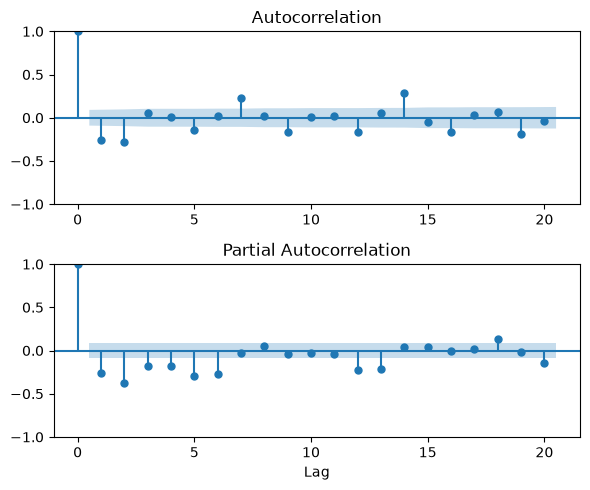

In [14]:
# autocorrelation plots
fig, axs = plt.subplots(2, figsize=(6,5))
plot_acf(df_plot['visits_return_log'], ax=axs[0], lags=20)
plot_pacf(df_plot['visits_return_log'], ax=axs[1], lags=20)
axs[1].set_xlabel('Lag')
plt.tight_layout()
plt.savefig('autocorrelation_foursquare.png',dpi=400)

## Gamestop

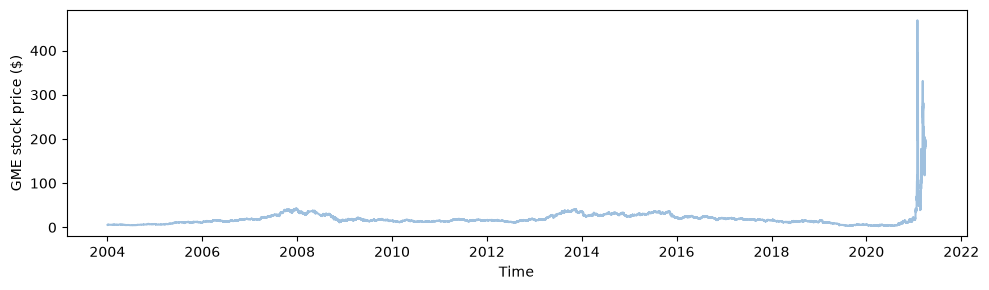

In [15]:
df = pd.read_csv('data/GME_1hour.csv', parse_dates=['DateTime'])
#df['DateTime'] = df['DateTime'].apply(lambda x : datetime.strptime(x, '%Y-%m-%d %H:%M:%S').date())
#df['DateTime'] = df['DateTime'].apply(lambda x : np.datetime64(x))
df = df[['DateTime', 'Close']]

fig,ax = plt.subplots(1,1,figsize=(10,3))
ax.plot(df['DateTime'],df['Close'],'-',color='#9FC0DE')

ax.set_ylabel('GME stock price ($)')
ax.set_xlabel('Time')
plt.tight_layout()
plt.savefig('gme_price.png', dpi=400)

In [16]:
df_gamestop_tweets = pd.read_csv('data/GME_tweet_volume_timeline.csv', parse_dates=['time'])
df_gamestop_tweets.head()

,time,tweets
0,2020-12-01 00:00:00,296
1,2020-12-01 01:00:00,207
2,2020-12-01 02:00:00,168
3,2020-12-01 03:00:00,147
4,2020-12-01 04:00:00,111


In [17]:
# EXERCISE: smooth the time series and transform them to make them stationary